# Figure S20 — Dacite–melt-inclusion mixing comparisons

## 1. Imports and shared Science Advances setup

This section reproduces the publication settings from `00_Setup/Plotting_Setup.ipynb`. There are no custom functions.

In [1]:
from pathlib import Path
import hashlib
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
import numpy as np
import pandas as pd
from PIL import Image

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300
PUBLICATION_FONT = 'Arial'

installed_font_names = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in installed_font_names:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT,
    'axes.labelsize': BASE_TEXT_SIZE_PT,
    'axes.titlesize': BASE_TEXT_SIZE_PT,
    'xtick.labelsize': BASE_TEXT_SIZE_PT,
    'ytick.labelsize': BASE_TEXT_SIZE_PT,
    'legend.fontsize': BASE_TEXT_SIZE_PT,
    'legend.title_fontsize': BASE_TEXT_SIZE_PT,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': False,
    'axes.spines.top': True,
    'axes.spines.right': True,
    'axes.linewidth': 0.5,
    'lines.linewidth': 0.75,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'savefig.dpi': EXPORT_DPI,
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})
print('Shared setup complete: Arial, 8-point text, 9-point bold panel labels, and 300 dpi export.')

Shared setup complete: Arial, 8-point text, 9-point bold panel labels, and 300 dpi export.


## 2. Figure S20 paths and plotting choices

This figure uses only the current S1 and S3 workbooks. S2 remains part of the required three-workbook package but is not needed for these data.

In [2]:
PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / 'SA_MI_Draft_FinalFigures_Work/DataSheets').is_dir():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from inside the Glacier Peak Efforts project.')

WORK_ROOT = PROJECT_ROOT / 'SA_MI_Draft_FinalFigures_Work'
CURRENT_DIRECTORY = WORK_ROOT / 'Nov6_AllFigures' / 'Figure_S20_Dacite_Mineral_Mixing'
OUTPUT_DIRECTORY = CURRENT_DIRECTORY / 'Figure_S20_Dacite_Mineral_Mixing_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

DATA_DIRECTORY = WORK_ROOT / 'DataSheets' / 'Updated_Oct20'
WORKBOOK_PATHS = {
    'S1': Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/GP_Combined/SEIMS_SEM_Raman_LAICPMS/Combining_All_Dechert_Data/Combining_All_Dechert_Data_S1_20261110.xlsx'),
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement} workbook not found: {path}')

PANEL_ELEMENTS = ['Sr', 'Rb', 'Ba', 'Zr', 'Y', 'Nb', 'Ce', 'La', 'Nd', 'Th', 'Yb', 'Hf']
ISOTOPE_BY_ELEMENT = {'Sr':'88Sr','Rb':'85Rb','Ba':'137Ba','Zr':'90Zr','Y':'89Y','Nb':'93Nb','Ce':'140Ce','La':'139La','Nd':'146Nd','Th':'232Th','Yb':'171Yb','Hf':'178Hf'}
SAMPLE_ORDER = ['74D', '74A', '75', '76A']
SAMPLE_COLORS = {'74D':'#F4A261','74A':'#D55E00','75':'#56B4E9','76A':'#0072B2'}
SAMPLE_LABELS = {'74D':'B Middle','74A':'B Base','75':'G Top','76A':'G Middle'}
PHASE_MARKERS = {'plag':'o','pxy':'s'}
PHASE_LABELS = {'plag':'Plagioclase-hosted MI','pxy':'Pyroxene-hosted MI'}
KUEHN_COLORS = {'B':'#D4A017','G':'#006D77'}
B_DACITE_COLOR = '#9E2A4F'
FRACTIONATION_CASES = {'Standard MI-dacite mixing':(0.00,0.00),'5% plag removal':(0.05,0.00),'10% plag removal':(0.10,0.00),'5% pyroxene removal':(0.00,0.05),'10% pyroxene removal':(0.00,0.10)}
MODEL_STYLES = {'Standard MI-dacite mixing':('#111111','-',0.95),'5% plag removal':('#6A3D9A','-',0.78),'10% plag removal':('#6A3D9A','--',0.78),'5% pyroxene removal':('#117733','-',0.78),'10% pyroxene removal':('#117733','--',0.78)}

SOURCE_HASHES_BEFORE = {key: hashlib.sha256(path.read_bytes()).hexdigest() for key, path in WORKBOOK_PATHS.items()}
print(f'Source directory: {DATA_DIRECTORY}')
print(f'Output directory: {OUTPUT_DIRECTORY}')

Source directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20
Output directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S20_Dacite_Mineral_Mixing/Figure_S20_Dacite_Mineral_Mixing_Final


## 3. Read and prepare the Figure S20 data

In [3]:
mi_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Hosts_Plag_Pxy')
host_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='TE_MI_Replicates')
vein_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Dacite_Vein')
whole_rock_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Whole_Rock')
kuehn_source = pd.read_excel(WORKBOOK_PATHS['S3'], sheet_name='Kuehn2009')

mi_work = mi_source.copy()
mi_work['sample_key'] = pd.NA
for sample_key in SAMPLE_ORDER:
    mi_work.loc[mi_work['base_name'].astype(str).str.startswith(sample_key), 'sample_key'] = sample_key
mi_work['phase_key'] = mi_work['mineral_phase'].astype(str).str.strip().str.casefold().replace({'opx':'pxy'})
mi_work['base_name_lower'] = mi_work['base_name'].astype(str).str.strip().str.casefold()
mi_work['is_matrix_glass'] = mi_work['base_name_lower'].str.contains(r'(?:^|[_\s-])mtx(?:$|[_\s-])', regex=True, na=False) | mi_work['base_name_lower'].str.contains('matrix glass', regex=False, na=False) | mi_work['phase_key'].isin(['mtx','matrix','matrix glass','groundmass glass'])
mi_work['discard_sims_yes'] = mi_work['Discard_SIMS'].fillna('').astype(str).str.strip().str.casefold().eq('yes')
mi_filter = ~mi_work['is_matrix_glass'] & ~mi_work['discard_sims_yes'] & mi_work['sample_key'].isin(SAMPLE_ORDER) & mi_work['phase_key'].isin(PHASE_MARKERS)

mi = mi_work.loc[mi_filter, ['base_name','sample_key','phase_key','SiO2_SEMGlass_AnhydoNorm','K2O_SEMGlass_AnhydoNorm','SiO2_host','K2O_host']].copy()
mi['SiO2'] = pd.to_numeric(mi_work.loc[mi_filter,'SiO2_SEMGlass_AnhydoNorm'], errors='coerce')
mi['K2O'] = pd.to_numeric(mi_work.loc[mi_filter,'K2O_SEMGlass_AnhydoNorm'], errors='coerce')
for element, isotope in ISOTOPE_BY_ELEMENT.items():
    mi[element] = pd.to_numeric(mi_work.loc[mi_filter, f'{isotope}_TE_MI_mean'], errors='coerce')
    mi[f'{element}_std_1sigma'] = pd.to_numeric(mi_work.loc[mi_filter, f'{isotope}_TE_MI_std_1sigma'], errors='coerce')

host_work = host_source.copy()
host_work['sample_key'] = pd.NA
for sample_key in SAMPLE_ORDER:
    host_work.loc[host_work['base_name'].astype(str).str.startswith(sample_key), 'sample_key'] = sample_key
host_work['phase_key'] = host_work['mineral_phase'].astype(str).str.strip().str.casefold().replace({'opx':'pxy'})
host_work['base_name_lower'] = host_work['base_name'].astype(str).str.strip().str.casefold()
host_work['is_matrix_glass'] = host_work['base_name_lower'].str.contains(r'(?:^|[_\s-])mtx(?:$|[_\s-])', regex=True, na=False) | host_work['base_name_lower'].str.contains('matrix glass', regex=False, na=False) | host_work['phase_key'].isin(['mtx','matrix','matrix glass','groundmass glass'])
host_filter = ~host_work['is_matrix_glass'] & host_work['sample_key'].isin(SAMPLE_ORDER) & host_work['phase_key'].isin(PHASE_MARKERS) & host_work['base_name'].astype(str).isin(set(mi['base_name'].astype(str)))
host_spots = []
for _, row in host_work.loc[host_filter].iterrows():
    for spot in ['TE1','TE2']:
        spot_row = {'host_phase': row['phase_key']}
        for element, isotope in ISOTOPE_BY_ELEMENT.items():
            spot_row[element] = pd.to_numeric(row.get(f'{isotope}_{spot}_host'), errors='coerce')
        if any(pd.notna(spot_row[element]) for element in PANEL_ELEMENTS):
            host_spots.append(spot_row)
host_spots = pd.DataFrame(host_spots)

host_medians = pd.DataFrame(index=['SiO2','K2O'] + PANEL_ELEMENTS, columns=['plag','pxy'], dtype=float)
host_counts = pd.DataFrame(index=host_medians.index, columns=['plag','pxy'], dtype=int)
for x_element, host_column in [('SiO2','SiO2_host'), ('K2O','K2O_host')]:
    for phase in PHASE_MARKERS:
        values = pd.to_numeric(mi.loc[mi['phase_key'].eq(phase), host_column], errors='coerce').dropna()
        host_medians.loc[x_element, phase] = values.median()
        host_counts.loc[x_element, phase] = len(values)
for element in PANEL_ELEMENTS:
    for phase in PHASE_MARKERS:
        values = pd.to_numeric(host_spots.loc[host_spots['host_phase'].eq(phase), element], errors='coerce').dropna()
        host_medians.loc[element, phase] = values.median()
        host_counts.loc[element, phase] = len(values)

vein = vein_source.loc[vein_source['TE Sample'].notna()].copy()
for oxide in ['SiO2','K2O']:
    vein[oxide] = pd.to_numeric(vein_source.loc[vein.index, f'{oxide}_SEMGlass_AnhydoNorm'], errors='coerce')
for element, isotope in ISOTOPE_BY_ELEMENT.items():
    vein[element] = pd.to_numeric(vein_source.loc[vein.index, f'{isotope}_TE_ppm'], errors='coerce')

whole_rock = whole_rock_source.copy()
whole_rock['sample_key'] = whole_rock['Sample'].astype(str).str.replace('GP-','',regex=False)
whole_rock['SiO2'] = pd.to_numeric(whole_rock['SiO2_XRF_Anhydrous_wt_pct'], errors='coerce')
whole_rock['K2O'] = pd.to_numeric(whole_rock['K2O_XRF_Anhydrous_wt_pct'], errors='coerce')
for element in PANEL_ELEMENTS:
    whole_rock[element] = pd.to_numeric(whole_rock[f'{element}_ICPMS_ppm'], errors='coerce')

kuehn = kuehn_source.copy()
kuehn_text = kuehn['Analyzed Unit'].fillna('').astype(str) + ' | ' + kuehn['Sample ID'].fillna('').astype(str)
kuehn['Tephra'] = np.select([
    kuehn_text.str.contains(r'(?i)(?:\bbed\s*B(?:\b|[-\d])|(?:^|[/\s])B\d?\b)', regex=True),
    kuehn_text.str.contains(r'(?i)(?:\bbed\s*G(?:\b|-)|(?:^|[/\s])G\b)', regex=True),
], ['B','G'], default=pd.NA)
kuehn = kuehn.loc[kuehn['Tephra'].isin(['B','G'])].copy()
for element in ['SiO2','K2O'] + PANEL_ELEMENTS:
    kuehn[element] = pd.to_numeric(kuehn[element], errors='coerce')

print(f'Melt inclusions retained: {len(mi)}')
print(f'Host spots retained: {len(host_spots)}')
print(f'Kuehn rows retained: {len(kuehn)}')
print(f'Dacite-vein rows retained: {len(vein)}')
print(f'Whole-rock rows retained: {len(whole_rock)}')
display(host_counts)

Melt inclusions retained: 186
Host spots retained: 119
Kuehn rows retained: 18
Dacite-vein rows retained: 20
Whole-rock rows retained: 4


,plag,pxy
SiO2,46.0,70.0
K2O,46.0,70.0
Sr,51.0,14.0
Rb,51.0,2.0
Ba,51.0,8.0
Zr,22.0,68.0
Y,51.0,68.0
Nb,0.0,2.0
Ce,51.0,68.0
La,51.0,36.0


## 4. Calculate median endmembers and crystal-removal trajectories

In [4]:
MODEL_ELEMENTS = ['SiO2','K2O'] + PANEL_ELEMENTS
mi_endmember = mi[MODEL_ELEMENTS].median(numeric_only=True)
vein_endmember = vein[MODEL_ELEMENTS].median(numeric_only=True)
fractionated_endmembers = {}
for case, (plag_fraction, pxy_fraction) in FRACTIONATION_CASES.items():
    values = {}
    for element in MODEL_ELEMENTS:
        dacite_value = vein_endmember[element]
        plag_value = host_medians.loc[element, 'plag']
        pxy_value = host_medians.loc[element, 'pxy']
        if (plag_fraction > 0 and pd.isna(plag_value)) or (pxy_fraction > 0 and pd.isna(pxy_value)) or pd.isna(dacite_value):
            values[element] = np.nan
        else:
            values[element] = (dacite_value - plag_fraction * plag_value - pxy_fraction * pxy_value) / (1 - plag_fraction - pxy_fraction)
    fractionated_endmembers[case] = pd.Series(values)

mixing_fractions = np.linspace(0.0, 1.0, 11)
mixing_models = {}
for x_element, label_start in [('SiO2', 65), ('K2O', 77)]:
    mixing_models[x_element] = {}
    for panel_index, y_element in enumerate(PANEL_ELEMENTS):
        panel_label = chr(label_start + panel_index)
        mixing_models[x_element][panel_label] = {}
        for case in FRACTIONATION_CASES:
            endpoint = fractionated_endmembers[case]
            required = [mi_endmember[x_element], mi_endmember[y_element], endpoint[x_element], endpoint[y_element]]
            if all(pd.notna(value) for value in required):
                mixing_models[x_element][panel_label][case] = pd.DataFrame({
                    x_element: (1 - mixing_fractions) * mi_endmember[x_element] + mixing_fractions * endpoint[x_element],
                    y_element: (1 - mixing_fractions) * mi_endmember[y_element] + mixing_fractions * endpoint[y_element],
                })
            else:
                mixing_models[x_element][panel_label][case] = None

print('Calculated mixing model labels:')
print('SiO2:', list(mixing_models['SiO2']))
print('K2O:', list(mixing_models['K2O']))

Calculated mixing model labels:
SiO2: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L']
K2O: ['M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X']


## 5. Plot and export the two continuous-label S19 views

SiO₂ panels are A–L. K₂O panels continue as M–X.

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S20_Dacite_Mineral_Mixing/Figure_S20_Dacite_Mineral_Mixing_Final/Figure_S20_SiO2_vs_TE_Crystal_Removal


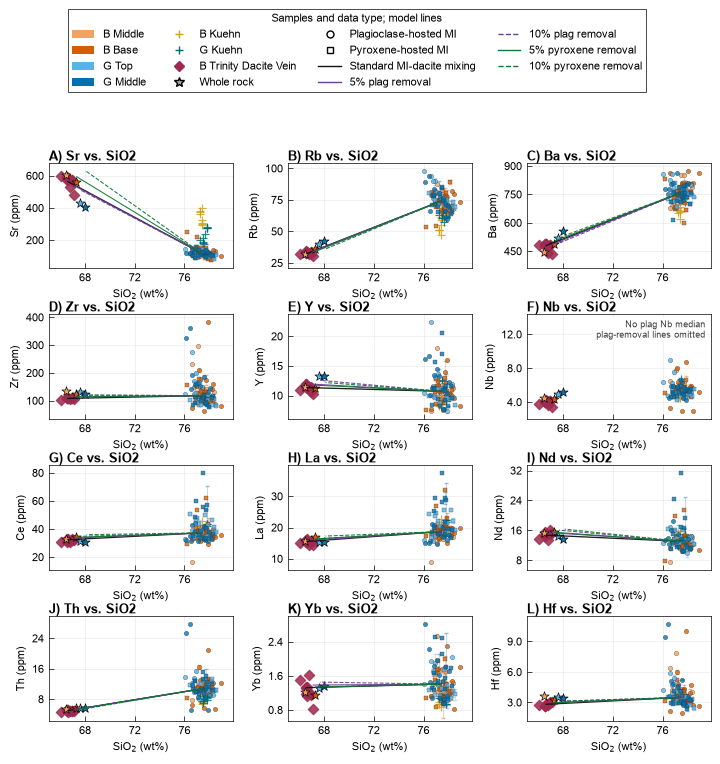

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S20_Dacite_Mineral_Mixing/Figure_S20_Dacite_Mineral_Mixing_Final/Figure_S20_K2O_vs_TE_Crystal_Removal


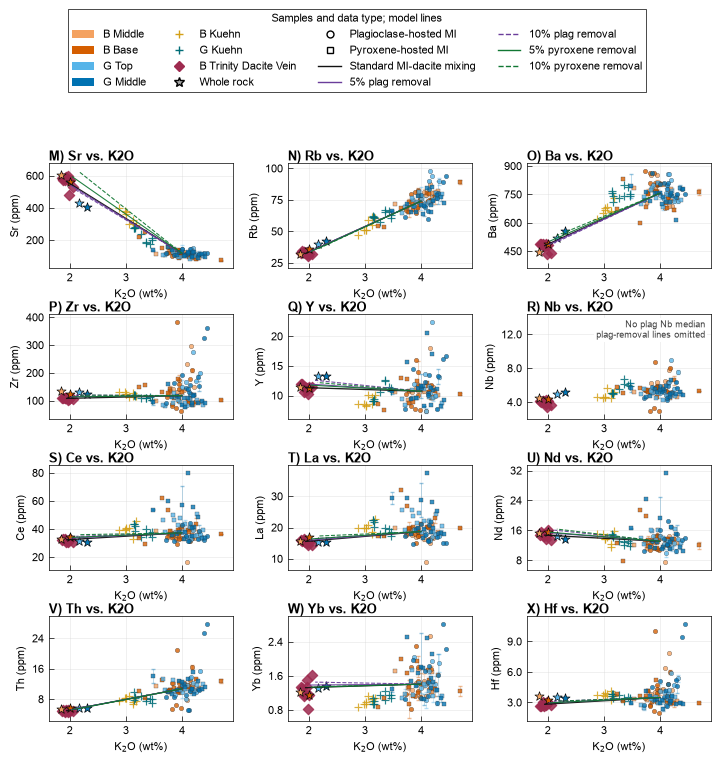

In [5]:
for x_element, output_stem_name, x_label, label_start in [
    ('SiO2', 'Figure_S20_SiO2_vs_TE_Crystal_Removal', 'SiO$_2$ (wt%)', 65),
    ('K2O', 'Figure_S20_K2O_vs_TE_Crystal_Removal', 'K$_2$O (wt%)', 77),
]:
    figure, axes = plt.subplots(4, 3, figsize=(DOUBLE_COLUMN_WIDTH_IN, MAXIMUM_RECOMMENDED_HEIGHT_IN))
    axes = np.asarray(axes).ravel()
    figure.subplots_adjust(left=0.075, right=0.988, bottom=0.065, top=0.78, wspace=0.30, hspace=0.44)

    for panel_index, (axis, y_element) in enumerate(zip(axes, PANEL_ELEMENTS)):
        panel_label = chr(label_start + panel_index)
        for tephra, color in KUEHN_COLORS.items():
            subset = kuehn.loc[kuehn['Tephra'].eq(tephra)].dropna(subset=[x_element, y_element])
            axis.scatter(subset[x_element], subset[y_element], marker='+', color=color, s=28, linewidths=0.85, alpha=0.84, zorder=2)

        for sample_key, color in SAMPLE_COLORS.items():
            for phase_key, marker in PHASE_MARKERS.items():
                subset = mi.loc[mi['sample_key'].eq(sample_key) & mi['phase_key'].eq(phase_key)].dropna(subset=[x_element, y_element])
                if subset.empty:
                    continue
                x_error = pd.to_numeric(subset.get(f'{x_element}_std_1sigma', pd.Series(index=subset.index, dtype=float)), errors='coerce')
                y_error = pd.to_numeric(subset[f'{y_element}_std_1sigma'], errors='coerce')
                if x_error.notna().any() or y_error.notna().any():
                    axis.errorbar(subset[x_element], subset[y_element], xerr=x_error if x_error.notna().any() else None, yerr=y_error if y_error.notna().any() else None, fmt='none', ecolor=color, elinewidth=0.42, capsize=1.1, alpha=0.42, zorder=2.4)
                axis.scatter(subset[x_element], subset[y_element], marker=marker, facecolor=color, edgecolor='0.18', linewidths=0.26, s=10.5, alpha=0.78, zorder=3)

        vein_subset = vein.dropna(subset=[x_element, y_element])
        axis.scatter(vein_subset[x_element], vein_subset[y_element], marker='D', color=B_DACITE_COLOR, s=28, linewidths=0.85, alpha=0.86, zorder=4)
        for case, style in MODEL_STYLES.items():
            model = mixing_models[x_element][panel_label][case]
            if model is not None:
                axis.plot(model[x_element], model[y_element], color=style[0], linestyle=style[1], linewidth=style[2], alpha=0.94, zorder=6)

        if y_element == 'Nb':
            axis.text(0.97, 0.95, 'No plag Nb median\nplag-removal lines omitted', transform=axis.transAxes, ha='right', va='top', fontsize=6.5, color='0.25', bbox={'facecolor':'white','edgecolor':'none','pad':1.4}, zorder=8)

        for sample_key, color in SAMPLE_COLORS.items():
            subset = whole_rock.loc[whole_rock['sample_key'].eq(sample_key)].dropna(subset=[x_element, y_element])
            axis.scatter(subset[x_element], subset[y_element], marker='*', s=48, facecolor=color, edgecolor='black', linewidths=0.48, alpha=0.98, zorder=4.5)

        x_values = pd.concat([mi[x_element], kuehn[x_element], vein[x_element], whole_rock[x_element]], ignore_index=True).dropna()
        y_values = pd.concat([mi[y_element], kuehn[y_element], vein[y_element], whole_rock[y_element]], ignore_index=True).dropna()
        for case in FRACTIONATION_CASES:
            model = mixing_models[x_element][panel_label][case]
            if model is not None:
                x_values = pd.concat([x_values, model[x_element]], ignore_index=True)
                y_values = pd.concat([y_values, model[y_element]], ignore_index=True)
        x_padding = 0.075 * (x_values.max() - x_values.min())
        y_padding = 0.09 * (y_values.max() - y_values.min())
        axis.set_xlim(x_values.min() - x_padding, x_values.max() + x_padding)
        axis.set_ylim(max(0, y_values.min() - y_padding), y_values.max() + y_padding)
        axis.set_xlabel(x_label)
        axis.set_ylabel(f'{y_element} (ppm)')
        axis.set_title(f'{panel_label}) {y_element} vs. {x_element}', loc='left', fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold', pad=2)
        axis.grid(True, color='#D9D9D9', linewidth=0.4, alpha=0.70)
        axis.set_axisbelow(True)
        axis.xaxis.set_major_locator(MaxNLocator(nbins=4))
        axis.yaxis.set_major_locator(MaxNLocator(nbins=4))
        if axis.get_ylim()[1] < 20:
            axis.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

    observation_handles = [Patch(facecolor=SAMPLE_COLORS[key], edgecolor='none', label=SAMPLE_LABELS[key]) for key in SAMPLE_ORDER]
    observation_handles += [
        Line2D([], [], linestyle='none', marker='+', color=KUEHN_COLORS['B'], markersize=6, label='B Kuehn'),
        Line2D([], [], linestyle='none', marker='+', color=KUEHN_COLORS['G'], markersize=6, label='G Kuehn'),
        Line2D([], [], linestyle='none', marker='D', color=B_DACITE_COLOR, markersize=5, label='B Trinity Dacite Vein'),
        Line2D([], [], linestyle='none', marker='*', markerfacecolor='0.65', markeredgecolor='black', markersize=7, label='Whole rock'),
        Line2D([], [], linestyle='none', marker='o', markerfacecolor='white', markeredgecolor='black', markersize=5, label=PHASE_LABELS['plag']),
        Line2D([], [], linestyle='none', marker='s', markerfacecolor='white', markeredgecolor='black', markersize=5, label=PHASE_LABELS['pxy']),
    ]
    model_handles = [Line2D([0,1], [0,0], color=style[0], linestyle=style[1], linewidth=1.0, label=case) for case, style in MODEL_STYLES.items()]
    legend = figure.legend(handles=observation_handles + model_handles, title='Samples and data type; model lines', loc='upper center', bbox_to_anchor=(0.5, 0.985), ncol=4, frameon=True, fancybox=False, facecolor='white', edgecolor='black', framealpha=1.0)
    legend.get_frame().set_linewidth(0.5)

    output_stem = OUTPUT_DIRECTORY / output_stem_name
    figure.savefig(output_stem.with_suffix('.png'), dpi=EXPORT_DPI, facecolor='white', transparent=False)
    figure.savefig(output_stem.with_suffix('.pdf'), facecolor='white', transparent=False)
    figure.savefig(output_stem.with_suffix('.svg'), facecolor='white', transparent=False)
    print(f'Saved: {output_stem}')
    plt.show()
    plt.close(figure)